# Sea-to-Air Transfer Decision Support

## tl;dr
One maintained allocation implementation replaces the historical notebooks. This analysis reruns the selected greedy policy, retains all decisions, and distinguishes full allocation from on-time fulfillment.

## Context & Methods
Scenario date: 2024-11-04. Assumed air transit: seven days. Candidate purchase lines must have method O02, originate outside SG, fit their entity quota, and improve arrival time. Transfer weight is charged once for the entire physical line. The result is a tested greedy policy, not a global optimum.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 4.8), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Open this notebook from inside the cloned project directory.")
ROOT = PROJECT_ROOT

import transfer
config = json.loads((ROOT / "config.json").read_text())
config

{'as_of': '2024-11-04',
 'air_days': 7,
 'policy': 'closest_quantity',
 'allow_air': True}

## Data
Four original Excel inputs are retained unchanged. Exact duplicate purchase rows are removed; two conflicting schedule rows are quarantined. One forecast buffer is created per material, after real sales orders.

In [2]:
summary, tables = transfer.run()
pd.Series(summary["input_profile"])

input_po_rows                      12542
exact_duplicate_po_rows_removed      732
ambiguous_po_rows_quarantined          2
po_rows_rejected                       0
usable_po_lines                     4713
input_so_rows                      10264
invalid_or_nonpositive_so_rows         0
sales_orders                       10264
buffer_demands                      1110
quota_month                          Nov
dtype: object

## Results
A fully allocated overdue order may still be late. Both counts are shown separately, and raw allocation rows allow independent reconciliation.

In [3]:
pd.Series({key: summary[key] for key in ["sales_orders", "fully_allocated_sales_orders", "fully_on_time_sales_orders", "transferred_po_lines", "air_weight_kg"]})

sales_orders                    10264.000
fully_allocated_sales_orders     7160.000
fully_on_time_sales_orders       5834.000
transferred_po_lines              181.000
air_weight_kg                   10185.873
dtype: float64

In [4]:
comparison = json.loads((ROOT / "results" / "candidate_comparison.json").read_text())
comparison_table = pd.DataFrame([{key: item[key] for key in ["candidate", "fully_allocated_sales_orders", "fully_on_time_sales_orders", "transferred_po_lines", "air_weight_kg"]} for item in comparison])
comparison_table

,candidate,fully_allocated_sales_orders,fully_on_time_sales_orders,transferred_po_lines,air_weight_kg
0,smallest_first,7159,5834,184,10245.297
1,earliest_due,7160,5834,181,10186.888
2,closest_quantity,7160,5834,181,10185.873
3,no_air,7008,5766,0,0.000


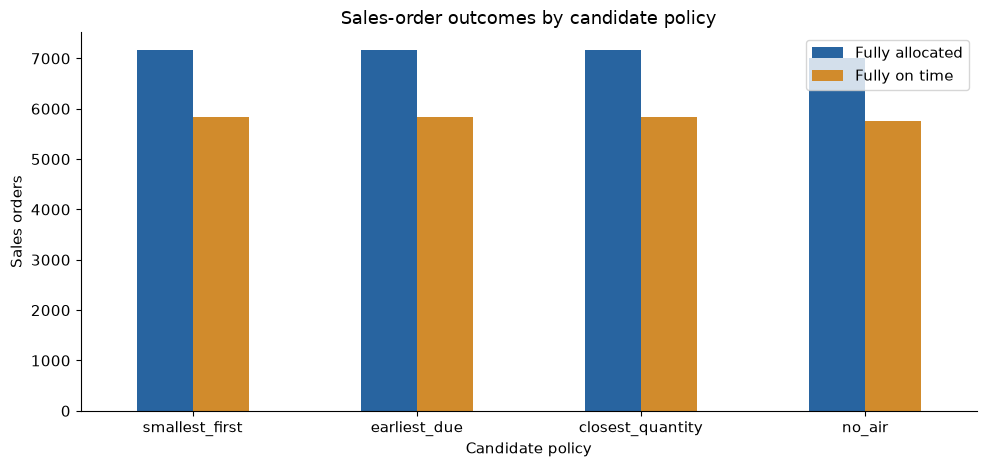

In [5]:
fig, ax = plt.subplots()
comparison_table.set_index("candidate")[["fully_allocated_sales_orders", "fully_on_time_sales_orders"]].plot.bar(ax=ax, color=["#2864a0", "#d18b2c"])
ax.set(title="Sales-order outcomes by candidate policy", xlabel="Candidate policy", ylabel="Sales orders")
ax.set_ylim(bottom=0)
ax.tick_params(axis="x", rotation=0)
ax.legend(["Fully allocated", "Fully on time"])
fig.tight_layout()
fig.savefig(ROOT / "results" / "policy_outcomes.png", dpi=150)
plt.show()

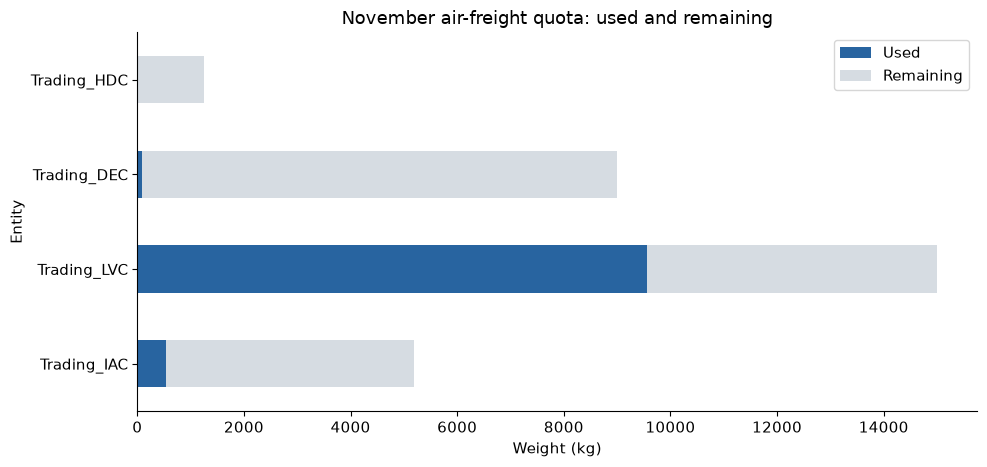

In [6]:
quota = tables["quota_remaining"].set_index("entity")
fig, ax = plt.subplots()
quota[["used_kg", "remaining_kg"]].plot.barh(stacked=True, ax=ax, color=["#2864a0", "#d6dce2"])
ax.set(title="November air-freight quota: used and remaining", xlabel="Weight (kg)", ylabel="Entity")
ax.set_xlim(left=0)
ax.legend(["Used", "Remaining"])
fig.tight_layout()
fig.savefig(ROOT / "results" / "quota_usage.png", dpi=150)
plt.show()

In [7]:
pd.Series(summary["checks"], name="Passed")

quota_nonnegative               True
stock_nonnegative               True
po_supply_conserved             True
unique_transfer_keys            True
candidate_method_and_country    True
demand_conserved                True
Name: Passed, dtype: bool

## Takeaways
The selected policy improves allocation and on-time order counts relative to the no-air baseline while respecting the checked constraints. Counts depend on the historical scenario date, transit assumption, quota, and buffer rule. Quarantined schedules need source clarification before they can be used as supply.

In [8]:
tables["transfers"].head(8)

,po_key,material,entity,country,original_method,quantity,weight_kg,sea_arrival,air_arrival
0,4512688444/180,ZB5AVB1,Trading_IAC,FR,O02,50.0,1.100,2025-01-29,2024-11-11
1,4512703795/3,VPL12N,Trading_DEC,FR,O02,64.0,46.336,2025-01-10,2024-11-11
2,4512629116/34,LA4DA1U,Trading_LVC,FR,O02,20.0,0.200,2024-11-13,2024-11-11
3,4512629116/35,LA4DA1U,Trading_LVC,FR,O02,20.0,0.200,2024-11-13,2024-11-11
4,4512629116/36,LA4DA1U,Trading_LVC,FR,O02,20.0,0.200,2024-11-13,2024-11-11
5,4512708700/173,VZ3,Trading_LVC,FR,O02,20.0,1.720,2025-01-22,2024-11-11
6,4512708700/108,LAD9R3,Trading_LVC,FR,O02,24.0,3.912,2025-01-10,2024-11-11
7,4512708700/109,LAD9R3,Trading_LVC,FR,O02,24.0,3.912,2025-01-10,2024-11-11
